# EMNIST Handwritten Letter Recognition — MobileNetV2

**Objective:** Compare ImageNet-pretrained MobileNetV2 (frozen feature extraction) with the same MobileNetV2 architecture trained from random initialization on the team's EMNIST letters dataset.

**Notebook organization:** Each code cell is preceded by Markdown explaining its purpose. Cells 1–23 preserve the original exploration and transfer-learning workflow, including the single-batch gradient experiments, the same optimizer and learning-rate settings, the same 20-epoch training schedule, and the original checkpoint naming. **No mixed-precision training is used.**

The original preprocessed `train.npz`, `val.npz`, and `test.npz` files are reused. Do not re-split or renormalize them. Keep the test set untouched until the final comparison.

**Execution note:** Running the whole notebook will retrain the transfer-learning model and the from-scratch model. To keep your previous trained transfer-learning results, leave the training cells unexecuted or use the pre-existing checkpoint rather than rerunning those cells. The saved transfer-learning checkpoint remains named `checkpoints/mobilenetv2_best.pth`.


## Cell 1 — Imports and GPU configuration

Load Python, PyTorch, TorchVision, NumPy, and Matplotlib. Identify whether CUDA is available and select the GPU when possible. This is the same environment check we used after setting up your RTX 5060 Ti. PyTorch models and batches must eventually be on the same device.

In [3]:
import sys
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.14
PyTorch: 2.9.1+cu130
TorchVision: 0.24.1+cu130
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


## Cell 2 — Inspect the working directory

`Path.cwd()` reports where the Jupyter kernel currently works. In our original notebook this was `models/MobileNet`, two directories below the repository root. Printing the folder contents helps us verify paths without hardcoding a Windows username.

In [4]:
PROJECT_DIR = Path.cwd()

print("Current working directory:")
print(PROJECT_DIR)
print("\nContents of this directory:")

for item in PROJECT_DIR.iterdir():
    print(item.name)

Current working directory:
C:\Users\Sheehizzle\Code\data4380\emnist-letter-recognition\models\MobileNet

Contents of this directory:
.ipynb_checkpoints
EMNIST_MobileNetV2_Preserved_Original_No_Mixed_Precision.ipynb


## Cell 3 — Locate the team's data folder

Navigate from `models/MobileNet` to the repository root with `parents[1]`. The teammate's exported files are stored in the repository-level `data` directory. This is the final path setup we used after you clarified the location.

In [5]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
REPO_DIR = PROJECT_DIR.parents[1]
DATA_DIR = REPO_DIR / "data"

print("Project directory:", PROJECT_DIR)
print("Repository root:", REPO_DIR)
print("Dataset directory:", DATA_DIR)

for name in ["train.npz", "val.npz", "test.npz"]:
    path = DATA_DIR / name
    print(f"{name}: {'Found' if path.is_file() else 'Missing'}")

Project directory: C:\Users\Sheehizzle\Code\data4380\emnist-letter-recognition\models\MobileNet
Repository root: C:\Users\Sheehizzle\Code\data4380\emnist-letter-recognition
Dataset directory: C:\Users\Sheehizzle\Code\data4380\emnist-letter-recognition\data
train.npz: Found
val.npz: Found
test.npz: Found


## Cell 4 — Load and inspect the training data

Each `.npz` file contains a NumPy image array (`X`), corresponding integer labels (`y`), and typically sample IDs. Images are already `float32` in `[0,1]`, so **do not divide by 255 again**. Shapes should be `(6837,28,28,1)` and `(6837,)`.

In [6]:
import numpy as np

with np.load(DATA_DIR / "train.npz", allow_pickle=False) as data:
    print("Available arrays:", data.files)
    X_train = data["X"]
    y_train = data["y"]

print("\nImage array shape:", X_train.shape)
print("Label array shape:", y_train.shape)
print("\nImage data type:", X_train.dtype)
print("Label data type:", y_train.dtype)
print("\nMinimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Available arrays: ['X', 'y', 'sample_id']

Image array shape: (6837, 28, 28, 1)
Label array shape: (6837,)

Image data type: float32
Label data type: int64

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Cell 5 — Visualize handwritten letters

Display ten real training images and their A–Z labels. The source combines uppercase and lowercase handwriting within each letter class. `.squeeze()` removes the one-channel axis for grayscale plotting, without changing the underlying data.

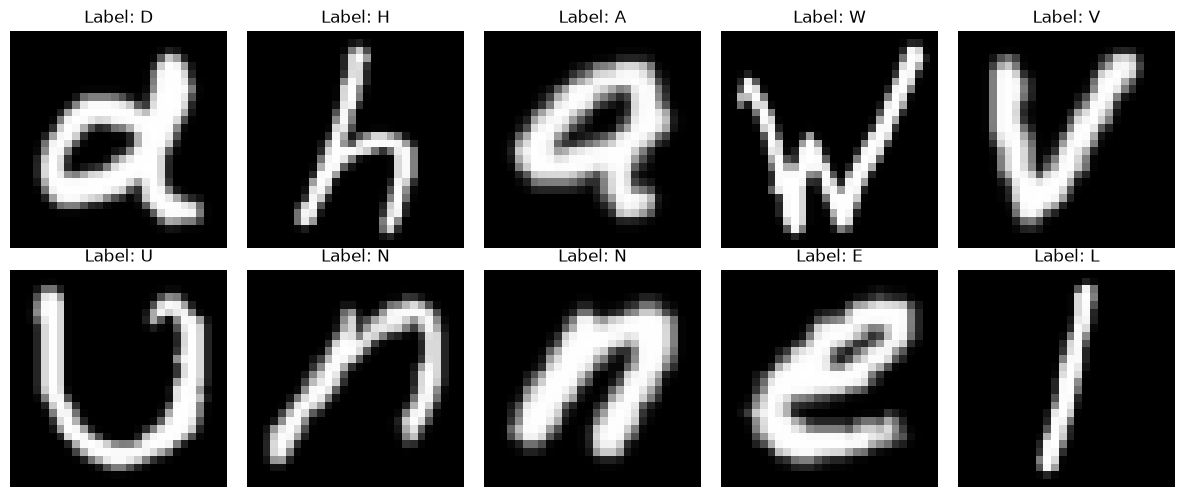

In [7]:
import matplotlib.pyplot as plt

CLASS_NAMES = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.ravel()

for i in range(10):
    image = X_train[i]
    label = y_train[i]
    axes[i].imshow(image.squeeze(), cmap="gray")
    axes[i].set_title(f"Label: {CLASS_NAMES[label]}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Cell 6 — Convert the training arrays to PyTorch tensors

PyTorch convolutions conventionally use channel-first `(N,C,H,W)` whereas the teammate's NumPy arrays are `(N,H,W,C)`. `torch.from_numpy` creates tensors and `.permute(0,3,1,2)` rearranges the axes. We keep the training data on the CPU and move batches to CUDA during training.

In [8]:
X_train_tensor = torch.from_numpy(X_train)
y_train_tensor = torch.from_numpy(y_train)

print("Original image shape:", X_train_tensor.shape)
X_train_tensor = X_train_tensor.permute(0, 3, 1, 2)

print("PyTorch image shape:", X_train_tensor.shape)
print("Label shape:", y_train_tensor.shape)
print("\nImage dtype:", X_train_tensor.dtype)
print("Label dtype:", y_train_tensor.dtype)
print("\nTensor device:", X_train_tensor.device)

Original image shape: torch.Size([6837, 28, 28, 1])
PyTorch image shape: torch.Size([6837, 1, 28, 28])
Label shape: torch.Size([6837])

Image dtype: torch.float32
Label dtype: torch.int64

Tensor device: cpu


## Cell 7 — Load validation and test tensors

Reuse the same file-reading and NHWC→NCHW conversion for validation and test sets. Keep the team's fixed splits intact. The 855-image validation set is used for model selection, while the separate 855-image test set is reserved for final evaluation.

In [9]:
def load_split(name):
    with np.load(DATA_DIR / f"{name}.npz", allow_pickle=False) as data:
        images = torch.from_numpy(data["X"])
        labels = torch.from_numpy(data["y"])
    images = images.permute(0, 3, 1, 2)
    return images, labels

X_val_tensor, y_val_tensor = load_split("val")
X_test_tensor, y_test_tensor = load_split("test")

print("Training:", X_train_tensor.shape)
print("Validation:", X_val_tensor.shape)
print("Testing:", X_test_tensor.shape)
print("\nValidation labels:", y_val_tensor.shape)
print("Testing labels:", y_test_tensor.shape)

Training: torch.Size([6837, 1, 28, 28])
Validation: torch.Size([855, 1, 28, 28])
Testing: torch.Size([855, 1, 28, 28])

Validation labels: torch.Size([855])
Testing labels: torch.Size([855])


## Cell 8 — Preprocess one image for pretrained MobileNetV2

The pretrained MobileNetV2 weights expect three input channels and ImageNet preprocessing. Replicate the one grayscale channel into three, then apply the weights' standard resize, center crop, and per-channel normalization. One sample makes the transformations easy to inspect.

In [10]:
from torchvision.models import MobileNet_V2_Weights

weights = MobileNet_V2_Weights.DEFAULT
preprocess = weights.transforms()

image = X_train_tensor[0]
print("Original shape:", image.shape)

image_rgb = image.repeat(3, 1, 1)
print("RGB shape:", image_rgb.shape)

image_processed = preprocess(image_rgb)
print("Processed shape:", image_processed.shape)
print("Minimum value:", image_processed.min().item())
print("Maximum value:", image_processed.max().item())

Original shape: torch.Size([1, 28, 28])
RGB shape: torch.Size([3, 28, 28])
Processed shape: torch.Size([3, 224, 224])
Minimum value: -2.1179039478302
Maximum value: 2.6395490169525146


## Cell 9 — Compare original and transformed images

ImageNet normalization changes the numerical range. Reverse it **only for display**, using `x = x_normalized * std + mean`. Matplotlib expects channels-last RGB `(H,W,C)`. Enlarging a 28×28 image to 224×224 interpolates pixels but does not introduce new image information.

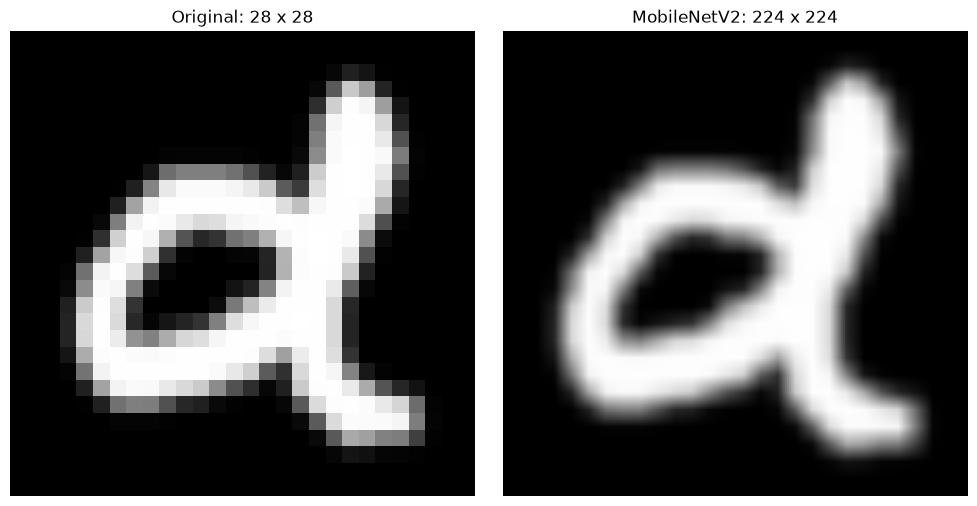

In [11]:
mean = torch.tensor(preprocess.mean).view(3, 1, 1)
std = torch.tensor(preprocess.std).view(3, 1, 1)

image_display = image_processed * std + mean
image_display = image_display.clamp(0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original: 28 x 28")
axes[0].axis("off")
axes[1].imshow(image_display.permute(1, 2, 0))
axes[1].set_title("MobileNetV2: 224 x 224")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## Cell 10 — Build the original pretrained transfer-learning model

Load ImageNet weights, freeze the feature extractor, replace the 1,000-class classifier with a randomly initialized 26-class linear layer, then move the network to CUDA. This matches our original **feature-extraction** experiment: only 33,306 classifier parameters train initially.

In [12]:
import torch.nn as nn

model = mobilenet_v2(weights=weights)

print("Original classifier:")
print(model.classifier)

for parameter in model.features.parameters():
    parameter.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 26)
model = model.to(device)

print("\nNew classifier:")
print(model.classifier)
print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

Original classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

New classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=26, bias=True)
)

Trainable parameters: 33306
Total parameters: 2257178


## Cell 11 — Trace feature-map shapes

A forward pass through `model.features` reveals how MobileNetV2 changes spatial size and channel count. The model converts an RGB image to a final feature tensor with 1,280 channels and a 7×7 spatial grid at 224×224 input size. Evaluation/inference mode prevents updates to running statistics.

In [13]:
x = image_processed.unsqueeze(0).to(device)
print("Input shape:", tuple(x.shape))
print()

model.eval()

with torch.inference_mode():
    for i, layer in enumerate(model.features):
        x = layer(x)
        print(
            f"Block {i:2d} | "
            f"{type(layer).__name__:22s} | "
            f"Output: {tuple(x.shape)}"
        )

print("\nFinal feature map:", tuple(x.shape))

Input shape: (1, 3, 224, 224)

Block  0 | Conv2dNormActivation   | Output: (1, 32, 112, 112)
Block  1 | InvertedResidual       | Output: (1, 16, 112, 112)
Block  2 | InvertedResidual       | Output: (1, 24, 56, 56)
Block  3 | InvertedResidual       | Output: (1, 24, 56, 56)
Block  4 | InvertedResidual       | Output: (1, 32, 28, 28)
Block  5 | InvertedResidual       | Output: (1, 32, 28, 28)
Block  6 | InvertedResidual       | Output: (1, 32, 28, 28)
Block  7 | InvertedResidual       | Output: (1, 64, 14, 14)
Block  8 | InvertedResidual       | Output: (1, 64, 14, 14)
Block  9 | InvertedResidual       | Output: (1, 64, 14, 14)
Block 10 | InvertedResidual       | Output: (1, 64, 14, 14)
Block 11 | InvertedResidual       | Output: (1, 96, 14, 14)
Block 12 | InvertedResidual       | Output: (1, 96, 14, 14)
Block 13 | InvertedResidual       | Output: (1, 96, 14, 14)
Block 14 | InvertedResidual       | Output: (1, 160, 7, 7)
Block 15 | InvertedResidual       | Output: (1, 160, 7, 7)
Block 1

## Cell 12 — Inspect an inverted residual block

MobileNetV2 uses inverted residual blocks: first expand channels with a 1×1 convolution, then apply a 3×3 depthwise convolution, and finally project to fewer channels with a 1×1 convolution. The selected Block 2 expands 16→96 channels and projects to 24, while stride 2 halves the feature-map dimensions.

In [14]:
block = model.features[2]
sample = image_processed.unsqueeze(0).to(device)
model.eval()

with torch.inference_mode():
    sample = model.features[0](sample)
    sample = model.features[1](sample)
    print("Input to Block 2:", tuple(sample.shape))
    print()
    for i, layer in enumerate(block.conv):
        sample = layer(sample)
        print(
            f"Stage {i}: "
            f"{type(layer).__name__:22s} "
            f"-> {tuple(sample.shape)}"
        )

Input to Block 2: (1, 16, 112, 112)

Stage 0: Conv2dNormActivation   -> (1, 96, 112, 112)
Stage 1: Conv2dNormActivation   -> (1, 96, 56, 56)
Stage 2: Conv2d                 -> (1, 24, 56, 56)
Stage 3: BatchNorm2d            -> (1, 24, 56, 56)


## Cell 13 — Examine actual convolutional parameters

A convolution weight tensor has shape `(output_channels, input_channels / groups, kernel_height, kernel_width)`. A depthwise convolution sets `groups` equal to the input-channel count, letting each channel have its own spatial filter. Inspect Block 2 to verify the expansion, depthwise, and projection weights rather than relying only on formulas.

In [15]:
block = model.features[2]

for i, stage in enumerate(block.conv):
    print(f"\nStage {i}: {type(stage).__name__}")
    for layer in stage.modules():
        if isinstance(layer, nn.Conv2d):
            print("  Input channels:", layer.in_channels)
            print("  Output channels:", layer.out_channels)
            print("  Kernel size:", layer.kernel_size)
            print("  Stride:", layer.stride)
            print("  Groups:", layer.groups)
            print("  Weight shape:", tuple(layer.weight.shape))
            print("  Conv parameters:", layer.weight.numel())

total = sum(p.numel() for p in block.parameters())
print("\nTotal Block 2 parameters:", total)


Stage 0: Conv2dNormActivation
  Input channels: 16
  Output channels: 96
  Kernel size: (1, 1)
  Stride: (1, 1)
  Groups: 1
  Weight shape: (96, 16, 1, 1)
  Conv parameters: 1536

Stage 1: Conv2dNormActivation
  Input channels: 96
  Output channels: 96
  Kernel size: (3, 3)
  Stride: (2, 2)
  Groups: 96
  Weight shape: (96, 1, 3, 3)
  Conv parameters: 864

Stage 2: Conv2d
  Input channels: 96
  Output channels: 24
  Kernel size: (1, 1)
  Stride: (1, 1)
  Groups: 1
  Weight shape: (24, 96, 1, 1)
  Conv parameters: 2304

Stage 3: BatchNorm2d

Total Block 2 parameters: 5136


## Cell 14 — Verify residual connections

Residual blocks can compute `y = F(x) + x` when the input and output shapes match. Block 2 changes dimensions, so its residual path is disabled. Block 3 preserves dimensions and adds its original input to the convolutional output. We verify that behavior numerically with `torch.allclose`.

In [16]:
block2 = model.features[2]
block3 = model.features[3]

print("Block 2 residual:", block2.use_res_connect)
print("Block 3 residual:", block3.use_res_connect)

x = image_processed.unsqueeze(0).to(device)
model.eval()

with torch.inference_mode():
    for layer in model.features[:3]:
        x = layer(x)

    residual = x
    transformed = block3.conv(x)
    output = block3(x)

    print("\nInput shape:", tuple(residual.shape))
    print("Transformed shape:", tuple(transformed.shape))
    print("Output shape:", tuple(output.shape))

    expected = transformed + residual
    print("\nOutput equals F(x) + x:",
          torch.allclose(output, expected, atol=1e-5))

Block 2 residual: False
Block 3 residual: True

Input shape: (1, 24, 56, 56)
Transformed shape: (1, 24, 56, 56)
Output shape: (1, 24, 56, 56)

Output equals F(x) + x: True


## Cell 15 — Build the original DataLoaders

`TensorDataset` keeps each image paired with its label. `DataLoader` creates batches of 64, shuffles only training data, and leaves the tensors on the CPU until needed. Windows/Jupyter uses `num_workers=0` for straightforward loading; `pin_memory=True` can speed supported GPU transfers.

In [17]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))
print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Batch device:", images.device)

Training batches: 107
Validation batches: 14
Testing batches: 14

Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])
Batch device: cpu


## Cell 16 — First forward pass on a full batch

Move one 64-image batch to the selected device, replicate grayscale channels, and apply the same pretrained MobileNetV2 transforms as for one image. A forward pass produces 26 unnormalized class scores (logits) per image, resulting in `(64,26)`.

In [18]:
images, labels = next(iter(train_loader))
images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("Original batch:", images.shape)
print("Device:", images.device)

images_rgb = images.repeat(1, 3, 1, 1)
print("\nRGB batch:", images_rgb.shape)

images_processed = preprocess(images_rgb)
print("Processed batch:", images_processed.shape)

model.eval()
with torch.inference_mode():
    outputs = model(images_processed)

print("\nModel output:", outputs.shape)
print("\nFirst image output scores:")
print(outputs[0])

Original batch: torch.Size([64, 1, 28, 28])
Device: cuda:0

RGB batch: torch.Size([64, 3, 28, 28])
Processed batch: torch.Size([64, 3, 224, 224])

Model output: torch.Size([64, 26])

First image output scores:
tensor([ 0.1922,  0.1577,  0.0466,  0.2629, -0.1033, -0.0818,  0.4620, -0.1387,
         0.1536, -0.1350, -0.1188,  0.1312,  0.2554, -0.2142,  0.0622,  0.0499,
         0.0010,  0.0542, -0.1184,  0.2039,  0.0461,  0.0725, -0.3502,  0.0015,
         0.0882, -0.4104], device='cuda:0')


## Cell 17 — Cross-entropy and prediction accuracy

A classification output consists of logits, not probabilities. Softmax converts each row to 26 class probabilities, while `argmax` selects the highest scoring class. `nn.CrossEntropyLoss` internally computes log-softmax, so it accepts raw logits and integer labels directly. Before training, accuracy should be near chance (1/26 ≈ 3.85%), though individual batches vary.

In [19]:
criterion = nn.CrossEntropyLoss()

loss = criterion(outputs, labels)
probabilities = torch.softmax(outputs, dim=1)
predictions = torch.argmax(outputs, dim=1)

correct = (predictions == labels).sum().item()
accuracy = correct / len(labels)

print("Batch loss:", loss.item())
print("Batch accuracy:", accuracy)
print("\nFirst image:")
print("Actual letter:", CLASS_NAMES[labels[0].item()])
print("Predicted letter:", CLASS_NAMES[predictions[0].item()])
print("Predicted probability:",
      probabilities[0, predictions[0]].item())
print("Sum of probabilities:",
      probabilities[0].sum().item())

Batch loss: 3.287562370300293
Batch accuracy: 0.015625

First image:
Actual letter: U
Predicted letter: G
Predicted probability: 0.05867801606655121
Sum of probabilities: 1.0


## Cell 18 — First gradient update (demonstration)

The original experiment used Adam with learning rate `0.001`. It calculates the loss, backpropagates gradients through the trainable classifier, and makes **one** optimizer update. We keep `model.features.eval()` during training to prevent the frozen feature extractor's BatchNorm running statistics from changing. The classifier is reset in Cell 20, so this one-step demonstration does not affect the main experiment.

In [20]:
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

model.train()
model.features.eval()

weights_before = model.classifier[1].weight.detach().clone()
optimizer.zero_grad()

outputs = model(images_processed)
loss = criterion(outputs, labels)
print("Loss before update:", loss.item())

loss.backward()
gradients = model.classifier[1].weight.grad

print("Mean absolute gradient:",
      gradients.abs().mean().item())

optimizer.step()

weights_after = model.classifier[1].weight.detach()
weight_change = (
    weights_after - weights_before
).abs().sum().item()

print("Total absolute weight change:", weight_change)

Loss before update: 3.294527530670166
Mean absolute gradient: 0.0032642153091728687
Total absolute weight change: 28.678720474243164


## Cell 19 — Evaluate after one optimizer step

Evaluate the same demonstration batch again without dropout or gradient tracking. This reveals whether its loss and accuracy changed after the update. Improving one training batch is not evidence of generalization; validation results later give a more meaningful check.

In [21]:
model.eval()

with torch.inference_mode():
    updated_outputs = model(images_processed)
    updated_loss = criterion(updated_outputs, labels)
    updated_predictions = updated_outputs.argmax(dim=1)
    correct = (updated_predictions == labels).sum().item()
    updated_accuracy = correct / len(labels)

print("Loss after update:", updated_loss.item())
print("Accuracy after update:", updated_accuracy)
print("Correct predictions:", correct, "/", len(labels))

Loss after update: 3.1932103633880615
Accuracy after update: 0.03125
Correct predictions: 2 / 64


## Cell 20 — Original first complete training epoch

This cell reproduces our original frozen-feature-extractor training procedure. It **resets only the new 26-class classifier**, initializes a fresh Adam optimizer at `0.001`, and runs one epoch across all 107 training batches. The validation pass runs without gradients and weights remain unchanged. Multiply per-batch mean loss by batch size so the shorter final batch is weighted correctly.

In [22]:
torch.manual_seed(42)

model.classifier[1] = nn.Linear(1280, 26).to(device)

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

def prepare_batch(images):
    images = images.to(device, non_blocking=True)
    images = images.repeat(1, 3, 1, 1)
    images = preprocess(images)
    return images

model.train()
model.features.eval()

train_loss = 0.0
train_correct = 0
train_total = 0

for batch_idx, (images, labels) in enumerate(train_loader):
    images = prepare_batch(images)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)
    train_loss += loss.item() * batch_size
    train_correct += (outputs.argmax(1) == labels).sum().item()
    train_total += batch_size

    if (batch_idx + 1) % 20 == 0:
        print(f"Completed batch {batch_idx + 1}/{len(train_loader)}")

train_loss /= train_total
train_accuracy = train_correct / train_total

model.eval()

val_loss = 0.0
val_correct = 0
val_total = 0

with torch.inference_mode():
    for images, labels in val_loader:
        images = prepare_batch(images)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        batch_size = labels.size(0)

        val_loss += loss.item() * batch_size
        val_correct += (outputs.argmax(1) == labels).sum().item()
        val_total += batch_size

val_loss /= val_total
val_accuracy = val_correct / val_total

print("\nEpoch 1 Results")
print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy:.4%}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4%}")

Completed batch 20/107
Completed batch 40/107
Completed batch 60/107
Completed batch 80/107
Completed batch 100/107

Epoch 1 Results
Training loss: 2.4721
Training accuracy: 42.5040%
Validation loss: 1.9657
Validation accuracy: 58.0117%


## Cell 21 — Original reusable train/validation functions

These functions are the same basic loops as the first epoch, without resetting the model. Calling `train_one_epoch()` continues updating the existing classifier, while `validate_one_epoch()` uses the held-out validation split. The `history` dictionary begins with the first epoch's values so all plots include the full run.

In [23]:
def train_one_epoch():
    model.train()
    model.features.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in train_loader:
        images = prepare_batch(images)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        n = labels.size(0)
        total_loss += loss.item() * n
        total_correct += (outputs.argmax(1) == labels).sum().item()
        total_samples += n

    return total_loss / total_samples, total_correct / total_samples


@torch.inference_mode()
def validate_one_epoch():
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in val_loader:
        images = prepare_batch(images)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        n = labels.size(0)
        total_loss += loss.item() * n
        total_correct += (outputs.argmax(1) == labels).sum().item()
        total_samples += n

    return total_loss / total_samples, total_correct / total_samples


history = {
    "train_loss": [train_loss],
    "train_accuracy": [train_accuracy],
    "val_loss": [val_loss],
    "val_accuracy": [val_accuracy]
}

print("Training and validation functions created.")
print("Epoch 1 results recorded.")

Training and validation functions created.
Epoch 1 results recorded.


## Cell 22 — Original remaining epochs and checkpoint

Continue the original feature-extraction experiment from Epoch 2, up to a 20-epoch total. Save the state dictionary whenever validation loss improves by at least `0.0001`; stop after five epochs without sufficient improvement. Restore the best checkpoint at the end. This preserves the original `checkpoints/mobilenetv2_best.pth` path and **does not use mixed precision**. Re-running this cell continues the already-trained model, so run only once per experiment.

In [24]:
import time

MAX_EPOCHS = 20
PATIENCE = 5
MIN_DELTA = 0.0001

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "mobilenetv2_best.pth"

best_val_loss = min(history["val_loss"])
best_epoch = history["val_loss"].index(best_val_loss) + 1
epochs_without_improvement = 0

torch.save(model.state_dict(), CHECKPOINT_PATH)

start_time = time.perf_counter()

for epoch in range(len(history["train_loss"]) + 1, MAX_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch()
    val_loss, val_acc = validate_one_epoch()

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(f"\nEpoch {epoch}/{MAX_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2%}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2%}")

    if val_loss < best_val_loss - MIN_DELTA:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print("New best model saved!")
    else:
        epochs_without_improvement += 1
        print(f"No improvement: {epochs_without_improvement}/{PATIENCE}")

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

training_time = time.perf_counter() - start_time

model.load_state_dict(
    torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
)

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Additional training time: {training_time:.1f} seconds")
print("Best model restored.")


Epoch 2/20
Train Loss: 1.6930 | Train Acc: 62.10%
Val Loss:   1.5462 | Val Acc:   61.87%
New best model saved!

Epoch 3/20
Train Loss: 1.3771 | Train Acc: 67.62%
Val Loss:   1.3281 | Val Acc:   67.13%
New best model saved!

Epoch 4/20
Train Loss: 1.2022 | Train Acc: 70.72%
Val Loss:   1.1958 | Val Acc:   69.59%
New best model saved!

Epoch 5/20
Train Loss: 1.0838 | Train Acc: 73.19%
Val Loss:   1.1021 | Val Acc:   71.58%
New best model saved!

Epoch 6/20
Train Loss: 0.9946 | Train Acc: 74.70%
Val Loss:   1.0294 | Val Acc:   71.93%
New best model saved!

Epoch 7/20
Train Loss: 0.9318 | Train Acc: 75.66%
Val Loss:   0.9847 | Val Acc:   73.10%
New best model saved!

Epoch 8/20
Train Loss: 0.8786 | Train Acc: 76.83%
Val Loss:   0.9335 | Val Acc:   74.62%
New best model saved!

Epoch 9/20
Train Loss: 0.8354 | Train Acc: 78.06%
Val Loss:   0.9029 | Val Acc:   75.09%
New best model saved!

Epoch 10/20
Train Loss: 0.7969 | Train Acc: 78.60%
Val Loss:   0.8710 | Val Acc:   75.20%
New best mode

## Cell 23 — Original training curves

Plot training versus validation accuracy and cross-entropy loss across completed epochs, then report the best validation accuracy and minimum validation loss. Your original run reached 78.95% best validation accuracy and 0.7100 minimum validation loss; a fresh run may vary. This cell just plots stored history and doesn't retrain anything.

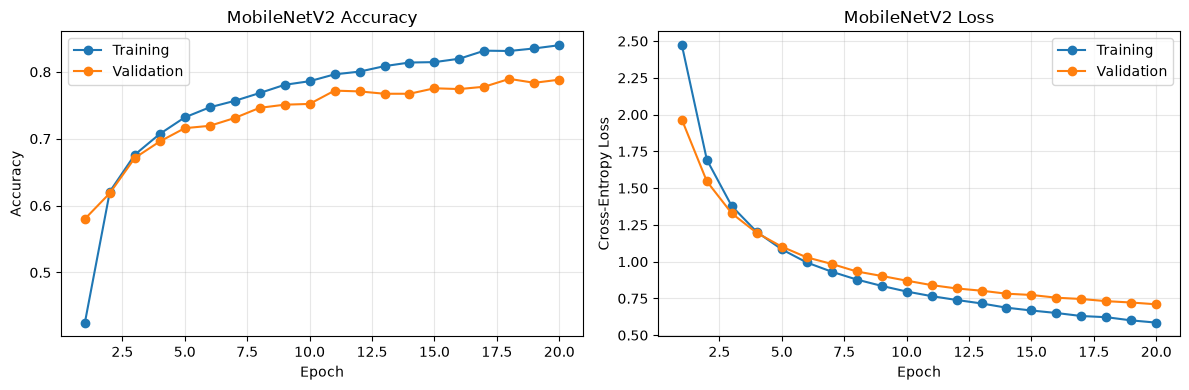

Epochs completed: 20
Best validation accuracy: 78.95%
Lowest validation loss: 0.7100


In [25]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_accuracy"], label="Training", marker="o")
axes[0].plot(epochs, history["val_accuracy"], label="Validation", marker="o")
axes[0].set_title("MobileNetV2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_loss"], label="Training", marker="o")
axes[1].plot(epochs, history["val_loss"], label="Validation", marker="o")
axes[1].set_title("MobileNetV2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Epochs completed:", len(history["train_loss"]))
print("Best validation accuracy:",
      f"{max(history['val_accuracy']):.2%}")
print("Lowest validation loss:",
      f"{min(history['val_loss']):.4f}")

# Experiment 2 — MobileNetV2 from scratch

The **preceding transfer-learning cells preserve the original workflow**. The following cells are new and do not overwrite `model` or `mobilenetv2_best.pth`.

We use the same MobileNetV2 architecture, 26 output classes, 64-image batches, fixed training/validation/test splits, and preprocessing function. `weights=None` initializes parameters from scratch; the entire feature extractor and classifier are trainable. For an initially controlled comparison we start with 20 epochs, early-stopping patience 5, and Adam learning rate 0.001 (as in the original transfer experiment). Because substantially more parameters are trained, this setting may need further tuning based **only on validation data**.


## Cell 24 — Initialize the from-scratch model

Create a separate `scratch_model` rather than overwriting the pretrained `model`. Use `weights=None`, which prevents loading ImageNet weights. All learnable parameters begin trainable. The model architecture is unchanged, so differences in results can be attributed mainly to initialization and training regime, subject to randomness.

In [26]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

scratch_model = mobilenet_v2(weights=None, num_classes=26).to(device)

scratch_total = sum(p.numel() for p in scratch_model.parameters())
scratch_trainable = sum(
    p.numel() for p in scratch_model.parameters()
    if p.requires_grad
)

print("Scratch model total parameters:", scratch_total)
print("Scratch model trainable parameters:", scratch_trainable)
print("Classifier:", scratch_model.classifier)
print("Device:", next(scratch_model.parameters()).device)

Scratch model total parameters: 2257178
Scratch model trainable parameters: 2257178
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=26, bias=True)
)
Device: cuda:0


## Cell 25 — Define independent scratch training functions

The scratch model must train **all** layers, including its feature extractor and BatchNorm running statistics. Unlike frozen-feature training, use `scratch_model.train()` without switching the features back to evaluation mode. This section defines a separate optimizer and metrics history, so the pretrained results are not modified. We reuse `prepare_batch` and `criterion` with ordinary FP32 training.

In [27]:
scratch_optimizer = torch.optim.Adam(
    scratch_model.parameters(),
    lr=0.001
)

scratch_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

def train_scratch_one_epoch():
    scratch_model.train()

    total_loss, total_correct, total_samples = 0.0, 0, 0

    for images, labels in train_loader:
        images = prepare_batch(images)
        labels = labels.to(device, non_blocking=True)

        scratch_optimizer.zero_grad()
        outputs = scratch_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        scratch_optimizer.step()

        n = labels.size(0)
        total_loss += loss.item() * n
        total_correct += (outputs.argmax(1) == labels).sum().item()
        total_samples += n

    return total_loss / total_samples, total_correct / total_samples


@torch.inference_mode()
def validate_scratch_one_epoch():
    scratch_model.eval()

    total_loss, total_correct, total_samples = 0.0, 0, 0

    for images, labels in val_loader:
        images = prepare_batch(images)
        labels = labels.to(device, non_blocking=True)

        outputs = scratch_model(images)
        loss = criterion(outputs, labels)

        n = labels.size(0)
        total_loss += loss.item() * n
        total_correct += (outputs.argmax(1) == labels).sum().item()
        total_samples += n

    return total_loss / total_samples, total_correct / total_samples

print("Scratch training and validation functions created.")

Scratch training and validation functions created.


## Cell 26 — Train from scratch and preserve the best validation checkpoint

Train up to 20 epochs with the same batch size and loss criterion, selecting the model with the lowest validation loss. Save scratch checkpoints separately as `mobilenetv2_scratch_best.pth`, so the transfer-learning checkpoint remains untouched. `time.perf_counter` measures all scratch epochs, whereas the original transfer time variable excluded its first epoch.

In [28]:
SCRATCH_CHECKPOINT_PATH = CHECKPOINT_DIR / "mobilenetv2_scratch_best.pth"
SCRATCH_MAX_EPOCHS = 20
SCRATCH_PATIENCE = 5
SCRATCH_MIN_DELTA = 0.0001

scratch_best_val_loss = float("inf")
scratch_best_epoch = 0
scratch_no_improvement = 0
scratch_start = time.perf_counter()

for epoch in range(1, SCRATCH_MAX_EPOCHS + 1):
    scratch_train_loss, scratch_train_acc = train_scratch_one_epoch()
    scratch_val_loss, scratch_val_acc = validate_scratch_one_epoch()

    scratch_history["train_loss"].append(scratch_train_loss)
    scratch_history["train_accuracy"].append(scratch_train_acc)
    scratch_history["val_loss"].append(scratch_val_loss)
    scratch_history["val_accuracy"].append(scratch_val_acc)

    print(f"\nScratch Epoch {epoch}/{SCRATCH_MAX_EPOCHS}")
    print(f"Train Loss: {scratch_train_loss:.4f} | Train Acc: {scratch_train_acc:.2%}")
    print(f"Val Loss:   {scratch_val_loss:.4f} | Val Acc:   {scratch_val_acc:.2%}")

    if scratch_val_loss < scratch_best_val_loss - SCRATCH_MIN_DELTA:
        scratch_best_val_loss = scratch_val_loss
        scratch_best_epoch = epoch
        scratch_no_improvement = 0
        torch.save(scratch_model.state_dict(), SCRATCH_CHECKPOINT_PATH)
        print("New best scratch model saved!")
    else:
        scratch_no_improvement += 1
        print(f"No improvement: {scratch_no_improvement}/{SCRATCH_PATIENCE}")

    if scratch_no_improvement >= SCRATCH_PATIENCE:
        print("Scratch early stopping triggered.")
        break

scratch_training_time = time.perf_counter() - scratch_start
scratch_model.load_state_dict(
    torch.load(SCRATCH_CHECKPOINT_PATH, map_location=device, weights_only=True)
)

print("\nScratch training complete.")
print("Best epoch:", scratch_best_epoch)
print(f"Best validation loss: {scratch_best_val_loss:.4f}")
print(f"Training time: {scratch_training_time:.1f} seconds")


Scratch Epoch 1/20
Train Loss: 1.8562 | Train Acc: 43.69%
Val Loss:   2.9453 | Val Acc:   27.13%
New best scratch model saved!

Scratch Epoch 2/20
Train Loss: 0.6505 | Train Acc: 79.48%
Val Loss:   0.7571 | Val Acc:   76.37%
New best scratch model saved!

Scratch Epoch 3/20
Train Loss: 0.4036 | Train Acc: 87.39%
Val Loss:   0.4627 | Val Acc:   84.33%
New best scratch model saved!

Scratch Epoch 4/20
Train Loss: 0.3000 | Train Acc: 90.32%
Val Loss:   0.3941 | Val Acc:   87.84%
New best scratch model saved!

Scratch Epoch 5/20
Train Loss: 0.2361 | Train Acc: 91.97%
Val Loss:   0.4528 | Val Acc:   84.68%
No improvement: 1/5

Scratch Epoch 6/20
Train Loss: 0.2056 | Train Acc: 93.33%
Val Loss:   0.4248 | Val Acc:   85.03%
No improvement: 2/5

Scratch Epoch 7/20
Train Loss: 0.1937 | Train Acc: 93.36%
Val Loss:   0.3160 | Val Acc:   89.94%
New best scratch model saved!

Scratch Epoch 8/20
Train Loss: 0.1679 | Train Acc: 94.05%
Val Loss:   0.3668 | Val Acc:   87.25%
No improvement: 1/5

Scrat

## Cell 27 — Plot the two training histories

Compare feature-extraction and from-scratch learning curves. These graphs use **training and validation only**, so they can guide further experimentation without touching the final test data. Curves also help identify whether scratch learning is still improving at the 20-epoch budget.

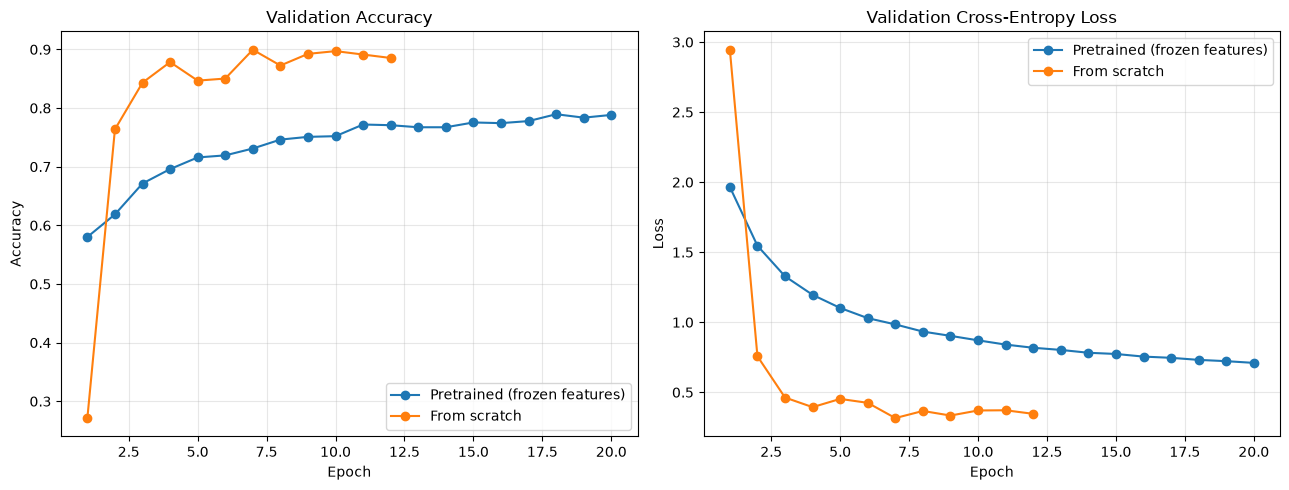

Pretrained: best validation accuracy = 78.95%
From scratch: best validation accuracy = 89.94%


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, metrics in [
    ("Pretrained (frozen features)", history),
    ("From scratch", scratch_history),
]:
    epochs = range(1, len(metrics["train_loss"]) + 1)
    axes[0].plot(epochs, metrics["val_accuracy"], marker="o", label=name)
    axes[1].plot(epochs, metrics["val_loss"], marker="o", label=name)

axes[0].set(title="Validation Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].set(title="Validation Cross-Entropy Loss", xlabel="Epoch", ylabel="Loss")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Pretrained: best validation accuracy =", f"{max(history['val_accuracy']):.2%}")
print("From scratch: best validation accuracy =", f"{max(scratch_history['val_accuracy']):.2%}")

# Final evaluation — held-out test set

**Run the following cells only after training choices are finalized.** The test split must not determine hyperparameters, epoch count, or which experiment to retrain. We evaluate the best validation-loss checkpoints for both models on identical samples, using exactly the same preprocessing.


## Cell 28 — Evaluate both models on the held-out test set

Use `eval()` and `torch.inference_mode()` for final predictions. The evaluation function collects all predicted classes and correct labels, reports test accuracy and cross-entropy loss, and supports precision/recall/F1 classification reports. The pretrained model and scratch model remain separate.

In [30]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

@torch.inference_mode()
def evaluate_test(net):
    net.eval()
    all_true, all_pred = [], []
    total_loss, total_correct, total_samples = 0.0, 0, 0

    for images, labels in test_loader:
        images = prepare_batch(images)
        labels = labels.to(device, non_blocking=True)

        outputs = net(images)
        loss = criterion(outputs, labels)
        predictions = outputs.argmax(dim=1)
        n = labels.size(0)

        total_loss += loss.item() * n
        total_correct += (predictions == labels).sum().item()
        total_samples += n

        all_true.extend(labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

    return {
        "accuracy": total_correct / total_samples,
        "loss": total_loss / total_samples,
        "y_true": np.array(all_true),
        "y_pred": np.array(all_pred),
    }

transfer_test = evaluate_test(model)
scratch_test = evaluate_test(scratch_model)

for name, result in [
    ("Transfer learning", transfer_test),
    ("From scratch", scratch_test),
]:
    print(f"\n{name}")
    print(f"Test accuracy: {result['accuracy']:.2%}")
    print(f"Test loss: {result['loss']:.4f}")
    print(classification_report(
        result["y_true"], result["y_pred"],
        labels=range(26), target_names=CLASS_NAMES,
        digits=3, zero_division=0
    ))


Transfer learning
Test accuracy: 80.70%
Test loss: 0.7054
              precision    recall  f1-score   support

           A      0.621     0.562     0.590        32
           B      0.750     0.818     0.783        33
           C      0.838     0.912     0.873        34
           D      0.900     0.818     0.857        33
           E      0.844     0.844     0.844        32
           F      0.750     0.882     0.811        34
           G      0.656     0.700     0.677        30
           H      0.861     0.939     0.899        33
           I      0.704     0.576     0.633        33
           J      0.906     0.853     0.879        34
           K      0.857     0.727     0.787        33
           L      0.694     0.735     0.714        34
           M      0.879     0.935     0.906        31
           N      0.724     0.700     0.712        30
           O      0.886     0.912     0.899        34
           P      0.879     0.906     0.892        32
           Q      0.66

## Cell 29 — Plot confusion matrices

A confusion matrix counts true classes by row and predicted classes by column. Large off-diagonal counts reveal difficult pairs such as G/Q or I/L. Using side-by-side matrices makes the pretrained and scratch models directly comparable.

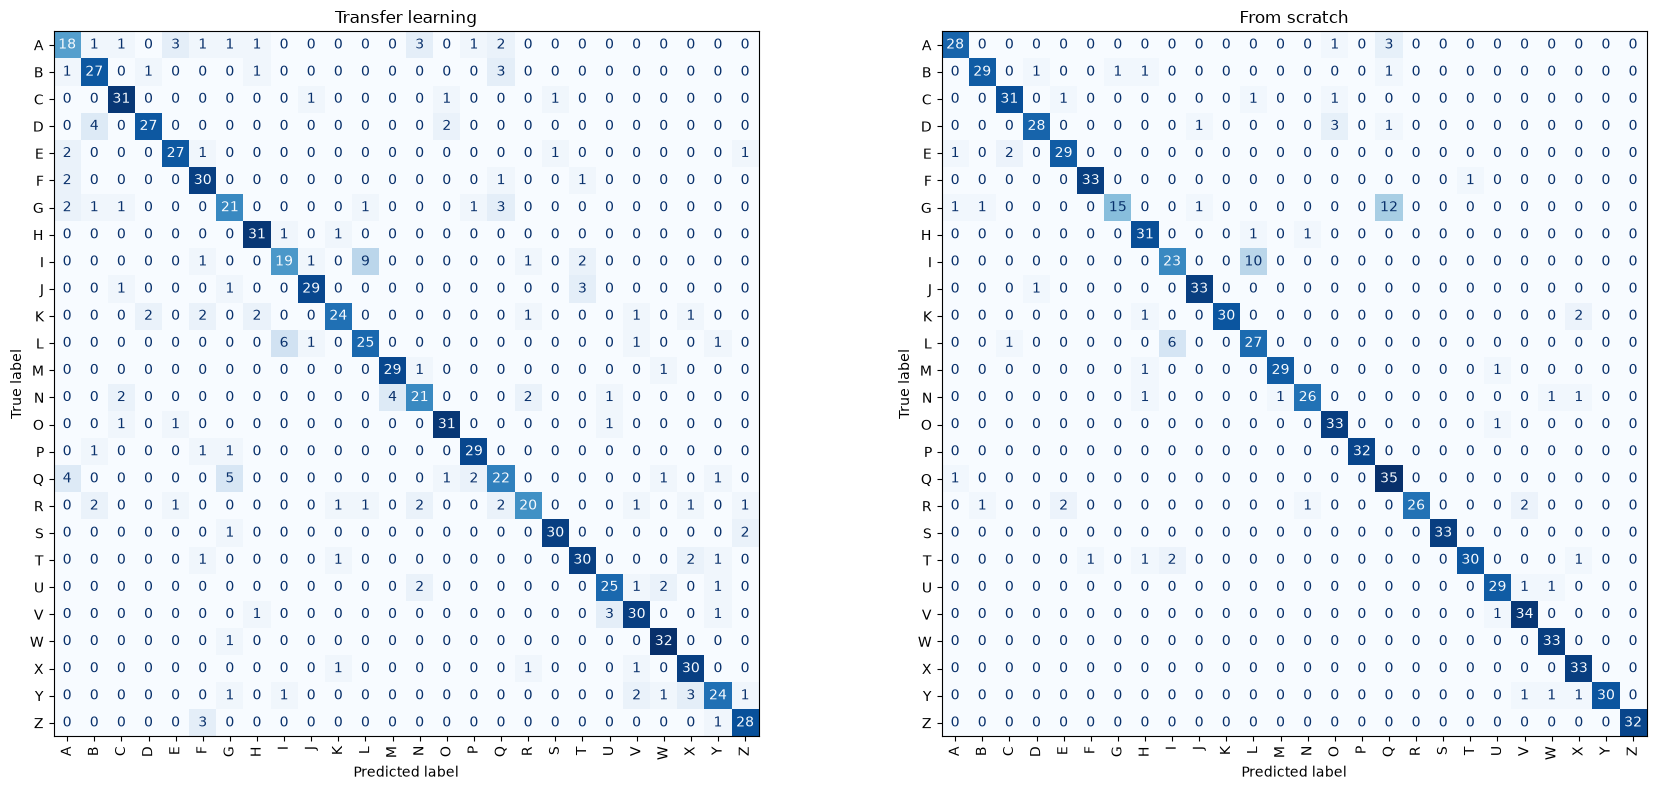

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, (name, result) in zip(axes, [
    ("Transfer learning", transfer_test),
    ("From scratch", scratch_test),
]):
    matrix = confusion_matrix(
        result["y_true"], result["y_pred"], labels=range(26)
    )
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASS_NAMES
    ).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Cell 30 — Summarize comparison with the team's CNN baseline

The team's existing Keras baseline reported 88.42% test accuracy and macro-F1 0.883. These baseline values are taken from its README, not recomputed in this notebook. Combine them with both MobileNet final test results after completing training. Record train/validation behavior and total training time separately because the original transfer timing omitted its first epoch.

In [32]:
baseline_test_accuracy = 0.8842
baseline_macro_f1 = 0.883

summary = [
    ("Team baseline CNN (reported)", baseline_test_accuracy, baseline_macro_f1),
    ("MobileNetV2 — pretrained", transfer_test["accuracy"],
     f1_score(transfer_test["y_true"], transfer_test["y_pred"], average="macro")),
    ("MobileNetV2 — from scratch", scratch_test["accuracy"],
     f1_score(scratch_test["y_true"], scratch_test["y_pred"], average="macro")),
]

print(f"{'Model':35s} {'Test Accuracy':>14s} {'Macro F1':>10s}")
print("-" * 63)
for name, accuracy, macro_f1 in summary:
    print(f"{name:35s} {accuracy:14.2%} {macro_f1:10.3f}")

Model                                Test Accuracy   Macro F1
---------------------------------------------------------------
Team baseline CNN (reported)                88.42%      0.883
MobileNetV2 — pretrained                    80.70%      0.804
MobileNetV2 — from scratch                  90.29%      0.902
